# Network Intrusion Detection System (NSL-KDD)

A machine learning system that classifies network traffic as normal or malicious
using the NSL-KDD dataset. Covers: SQL schema + queries over 100K+ records,
EDA, preprocessing, training/comparing Logistic Regression, Decision Tree, and
Random Forest, and evaluating with precision/recall/F1 — with extra focus on
false negatives, since a missed attack is far costlier than a false alarm.

In [1]:
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, precision_recall_fscore_support,
    accuracy_score
)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
RANDOM_STATE = 42

In [2]:
COLUMN_NAMES = [
    "duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes",
    "land", "wrong_fragment", "urgent", "hot", "num_failed_logins", "logged_in",
    "num_compromised", "root_shell", "su_attempted", "num_root",
    "num_file_creations", "num_shells", "num_access_files", "num_outbound_cmds",
    "is_host_login", "is_guest_login", "count", "srv_count", "serror_rate",
    "srv_serror_rate", "rerror_rate", "srv_rerror_rate", "same_srv_rate",
    "diff_srv_rate", "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count",
    "dst_host_same_srv_rate", "dst_host_diff_srv_rate",
    "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate",
    "dst_host_serror_rate", "dst_host_srv_serror_rate", "dst_host_rerror_rate",
    "dst_host_srv_rerror_rate", "label", "difficulty_level"
]

train_df = pd.read_csv("../data/raw/KDDTrain.txt", names=COLUMN_NAMES)
test_df = pd.read_csv("../data/raw/KDDTest.txt", names=COLUMN_NAMES)

train_df["dataset_split"] = "train"
test_df["dataset_split"] = "test"

print(f"Train records: {len(train_df):,}")
print(f"Test records:  {len(test_df):,}")
train_df.head()

Train records: 125,973
Test records:  22,544


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,root_shell,su_attempted,num_root,num_file_creations,num_shells,num_access_files,num_outbound_cmds,is_host_login,is_guest_login,count,srv_count,serror_rate,srv_serror_rate,rerror_rate,srv_rerror_rate,same_srv_rate,diff_srv_rate,srv_diff_host_rate,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty_level,dataset_split
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,2,0.0,0.0,0.0,0.0,1.00,0.00,0.00,150,25,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20,train
1,0,udp,other,SF,146,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,13,1,0.0,0.0,0.0,0.0,0.08,0.15,0.00,255,1,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15,train
2,0,tcp,private,S0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,123,6,1.0,1.0,0.0,0.0,0.05,0.07,0.00,255,26,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19,train
3,0,tcp,http,SF,232,8153,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,5,5,0.2,0.2,0.0,0.0,1.00,0.00,0.00,30,255,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21,train
4,0,tcp,http,SF,199,420,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,30,32,0.0,0.0,0.0,0.0,1.00,0.00,0.09,255,255,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21,train


In [3]:
ATTACK_CATEGORY_MAP = {
    "normal": "normal",
    "back": "dos", "land": "dos", "neptune": "dos", "pod": "dos", "smurf": "dos",
    "teardrop": "dos", "mailbomb": "dos", "processtable": "dos", "udpstorm": "dos",
    "apache2": "dos", "worm": "dos",
    "satan": "probe", "ipsweep": "probe", "nmap": "probe", "portsweep": "probe",
    "mscan": "probe", "saint": "probe",
    "guess_passwd": "r2l", "ftp_write": "r2l", "imap": "r2l", "phf": "r2l",
    "multihop": "r2l", "warezmaster": "r2l", "warezclient": "r2l", "spy": "r2l",
    "xlock": "r2l", "xsnoop": "r2l", "snmpguess": "r2l", "snmpgetattack": "r2l",
    "httptunnel": "r2l", "sendmail": "r2l", "named": "r2l",
    "buffer_overflow": "u2r", "loadmodule": "u2r", "rootkit": "u2r", "perl": "u2r",
    "sqlattack": "u2r", "xterm": "u2r", "ps": "u2r",
}

for df in (train_df, test_df):
    df["attack_category"] = df["label"].map(ATTACK_CATEGORY_MAP)

unmapped = set(train_df.loc[train_df["attack_category"].isna(), "label"].unique()) | \
           set(test_df.loc[test_df["attack_category"].isna(), "label"].unique())
print("Unmapped labels (if any):", unmapped)

Unmapped labels (if any): set()


In [4]:
conn = sqlite3.connect("../data/network_traffic.db")

with open("../sql/schema.sql") as f:
    conn.executescript(f.read())

full_df = pd.concat([train_df, test_df], ignore_index=True)
full_df.to_sql("network_traffic", conn, if_exists="append", index=False)

category_lookup = pd.DataFrame(
    sorted(ATTACK_CATEGORY_MAP.items()), columns=["label", "attack_category"]
)
category_lookup.to_sql("attack_category_map", conn, if_exists="append", index=False)

pd.read_sql("SELECT COUNT(*) AS total_records FROM network_traffic;", conn)

,total_records
0,148517


In [5]:
query_1 = """
SELECT dataset_split, attack_category, COUNT(*) AS n_records
FROM network_traffic
GROUP BY dataset_split, attack_category
ORDER BY dataset_split, n_records DESC;
"""
pd.read_sql(query_1, conn)

,dataset_split,attack_category,n_records
0,test,normal,9711
1,test,dos,7460
2,test,r2l,2885
3,test,probe,2421
4,test,u2r,67
5,train,normal,67343
6,train,dos,45927
7,train,probe,11656
8,train,r2l,995
9,train,u2r,52


In [6]:
query_2 = """
SELECT protocol_type,
       ROUND(AVG(src_bytes), 1)   AS avg_src_bytes,
       ROUND(AVG(dst_bytes), 1)   AS avg_dst_bytes,
       ROUND(AVG(serror_rate), 3) AS avg_serror_rate,
       COUNT(*) AS n_records
FROM network_traffic
WHERE attack_category != 'normal'
GROUP BY protocol_type
ORDER BY n_records DESC;
"""
pd.read_sql(query_2, conn)

,protocol_type,avg_src_bytes,avg_dst_bytes,avg_serror_rate,n_records
0,tcp,84188.6,36687.9,0.618,60127
1,icmp,429.2,0.0,0.000,7932
2,udp,32.7,8.8,0.019,3404


In [7]:
query_3 = """
SELECT service,
       SUM(CASE WHEN attack_category != 'normal' THEN 1 ELSE 0 END) AS attack_count,
       COUNT(*) AS total_count,
       ROUND(100.0 * SUM(CASE WHEN attack_category != 'normal' THEN 1 ELSE 0 END) / COUNT(*), 1) AS attack_pct
FROM network_traffic
GROUP BY service
HAVING total_count > 50
ORDER BY attack_pct DESC
LIMIT 10;
"""
pd.read_sql(query_3, conn)

,service,attack_count,total_count,attack_pct
0,whois,733,733,100.0
1,vmnet,660,660,100.0
2,uucp_path,735,735,100.0
3,uucp,830,830,100.0
4,systat,509,509,100.0
5,supdup,571,571,100.0
6,sunrpc,540,540,100.0
7,sql_net,263,263,100.0
8,rje,94,94,100.0
9,printer,80,80,100.0


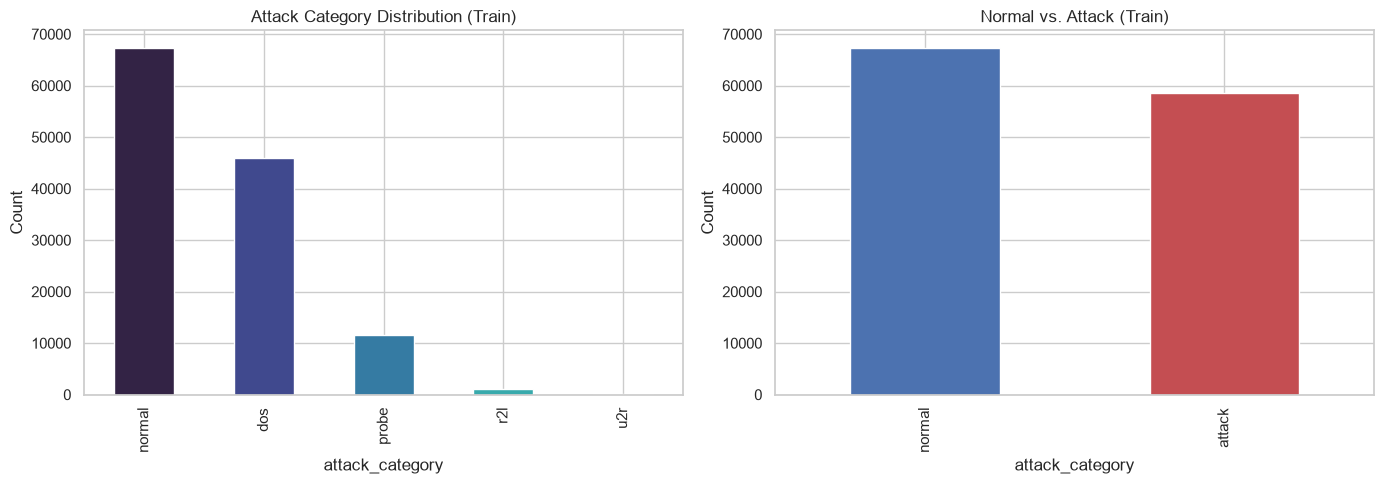

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

train_df["attack_category"].value_counts().plot(
    kind="bar", ax=axes[0], color=sns.color_palette("mako", 5)
)
axes[0].set_title("Attack Category Distribution (Train)")
axes[0].set_ylabel("Count")

is_attack = (train_df["attack_category"] != "normal").map({True: "attack", False: "normal"})
is_attack.value_counts().plot(kind="bar", ax=axes[1], color=["#4c72b0", "#c44e52"])
axes[1].set_title("Normal vs. Attack (Train)")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()

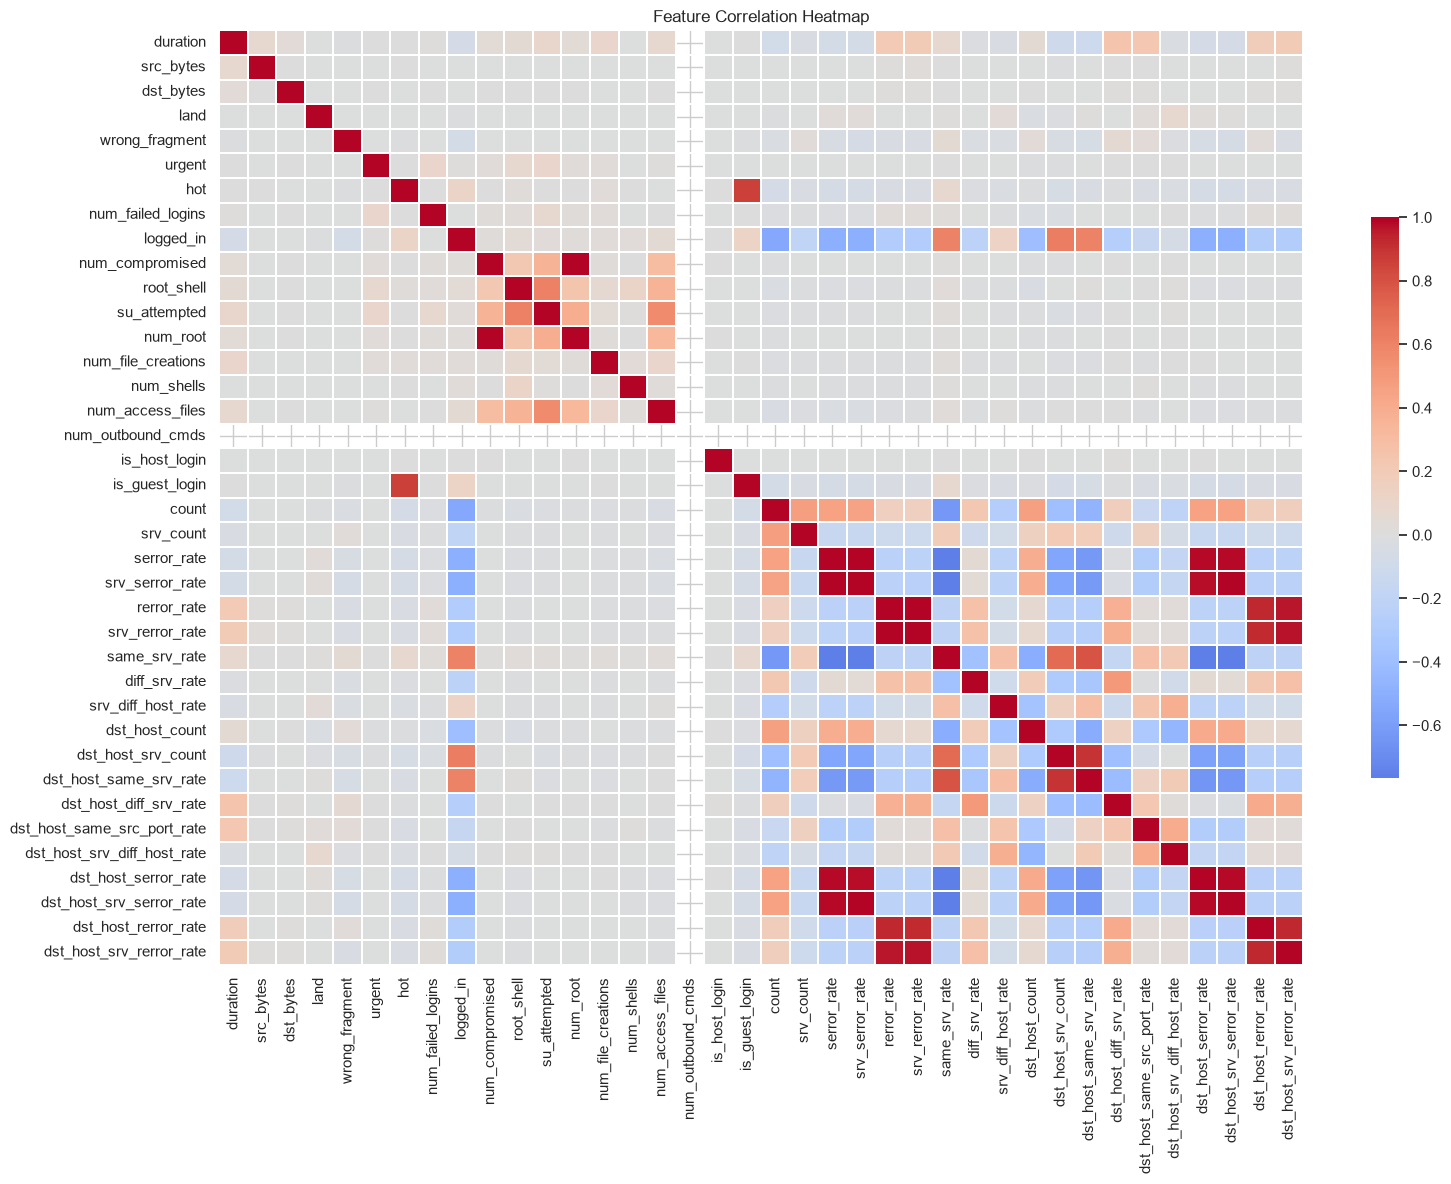

In [9]:
numeric_cols = train_df.select_dtypes(include=[np.number]).columns.drop("difficulty_level")
corr = train_df[numeric_cols].corr()

plt.figure(figsize=(16, 12))
sns.heatmap(corr, cmap="coolwarm", center=0, linewidths=0.3, cbar_kws={"shrink": 0.6})
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

In [10]:
categorical_cols = ["protocol_type", "service", "flag"]
exclude_cols = categorical_cols + ["label", "attack_category", "difficulty_level", "dataset_split"]
numeric_cols = [c for c in COLUMN_NAMES if c not in exclude_cols]

encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    le.fit(pd.concat([train_df[col], test_df[col]]))
    train_df[col + "_enc"] = le.transform(train_df[col])
    test_df[col + "_enc"] = le.transform(test_df[col])
    encoders[col] = le

feature_cols = numeric_cols + [c + "_enc" for c in categorical_cols]

scaler = StandardScaler()
X_train = scaler.fit_transform(train_df[feature_cols])
X_test = scaler.transform(test_df[feature_cols])

y_train_binary = (train_df["attack_category"] != "normal").astype(int)
y_test_binary = (test_df["attack_category"] != "normal").astype(int)

y_train_multi = train_df["attack_category"]
y_test_multi = test_df["attack_category"]

print("Feature matrix shape (train/test):", X_train.shape, X_test.shape)
print(y_train_binary.value_counts(normalize=True).round(3))

Feature matrix shape (train/test): (125973, 41) (22544, 41)
attack_category
0    0.535
1    0.465
Name: proportion, dtype: float64


In [13]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
}

binary_predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train_binary)
    binary_predictions[name] = model.predict(X_test)
    print(f"Trained: {name}")

Trained: Logistic Regression
Trained: Decision Tree
Trained: Random Forest


In [14]:
def evaluate_binary(y_true, y_pred, model_name):
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="binary", pos_label=1
    )
    acc = accuracy_score(y_true, y_pred)
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    fnr = fn / (fn + tp)

    return {
        "Model": model_name,
        "Accuracy": round(acc, 4),
        "Precision": round(precision, 4),
        "Recall": round(recall, 4),
        "F1-Score": round(f1, 4),
        "False Negatives": int(fn),
        "False Negative Rate": round(fnr, 4),
    }

results = [evaluate_binary(y_test_binary, preds, name) for name, preds in binary_predictions.items()]
results_df = pd.DataFrame(results).sort_values("False Negative Rate")
results_df

,Model,Accuracy,Precision,Recall,F1-Score,False Negatives,False Negative Rate
1,Decision Tree,0.7780,0.9653,0.6328,0.7645,4712,0.3672
0,Logistic Regression,0.7539,0.9252,0.6177,0.7408,4906,0.3823
2,Random Forest,0.7699,0.9667,0.6170,0.7532,4915,0.3830


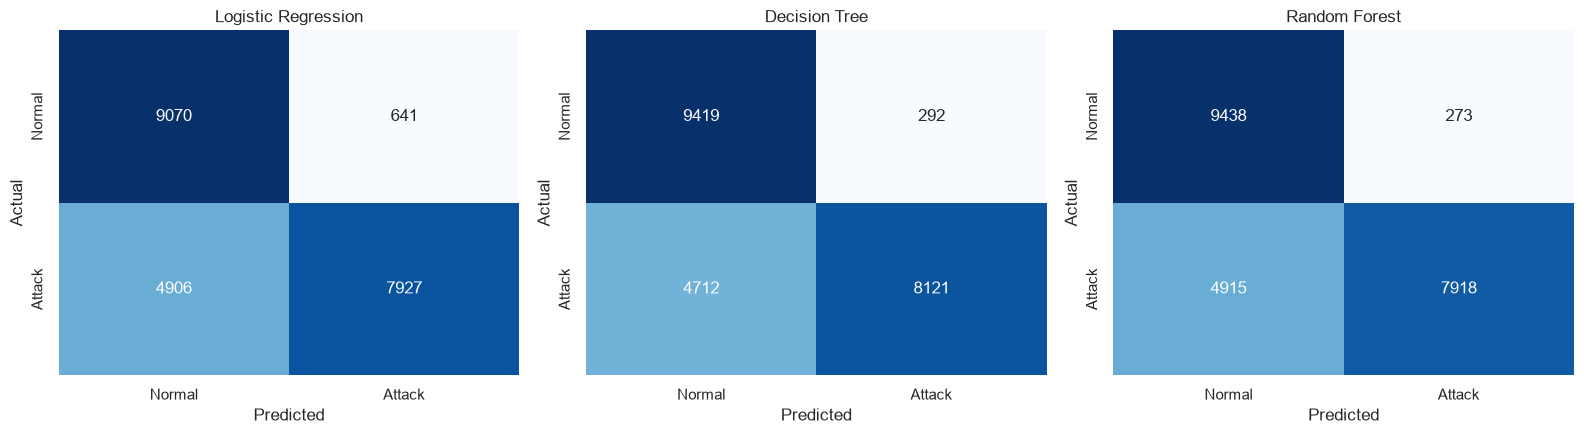

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, preds) in zip(axes, binary_predictions.items()):
    cm = confusion_matrix(y_test_binary, preds)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Normal", "Attack"], yticklabels=["Normal", "Attack"])
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

In [16]:
multi_predictions = {}
multi_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
}

for name, model in multi_models.items():
    model.fit(X_train, y_train_multi)
    multi_predictions[name] = model.predict(X_test)

print("Random Forest -- Multi-Class Classification Report\n")
print(classification_report(y_test_multi, multi_predictions["Random Forest"], zero_division=0))

Random Forest -- Multi-Class Classification Report

              precision    recall  f1-score   support

         dos       0.96      0.79      0.87      7460
      normal       0.65      0.97      0.78      9711
       probe       0.87      0.67      0.75      2421
         r2l       0.97      0.02      0.04      2885
         u2r       0.67      0.06      0.11        67

    accuracy                           0.75     22544
   macro avg       0.82      0.50      0.51     22544
weighted avg       0.82      0.75      0.71     22544



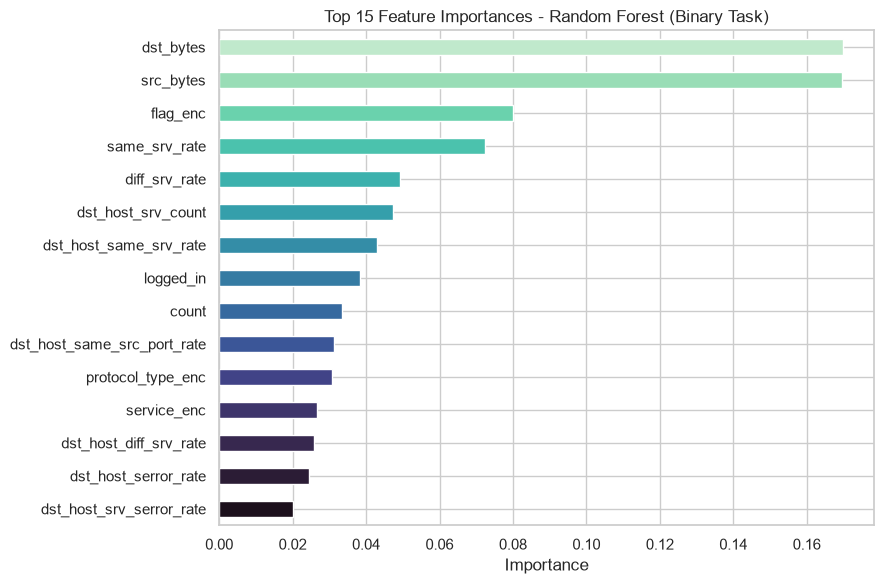

In [17]:
rf_binary = models["Random Forest"]
importances = pd.Series(rf_binary.feature_importances_, index=feature_cols).sort_values(ascending=False).head(15)

plt.figure(figsize=(9, 6))
importances.sort_values().plot(kind="barh", color=sns.color_palette("mako", 15))
plt.title("Top 15 Feature Importances - Random Forest (Binary Task)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## Model Selection & Conclusion



Contrary to the common assumption that ensembles always win, **Decision Tree**
achieved the lowest false negative rate (0.367) and best F1-score (0.765) of
the three models on this test set — edging out Random Forest (FNR 0.383) and
Logistic Regression (FNR 0.382). All three show precision above 0.92, meaning
false alarms are rare; the harder problem here is recall, driven by NSL-KDD's
test set deliberately including attack types never seen during training.

**Why false negatives drove model selection:** in a security context, a missed
attack (false negative) that reaches its target is far more costly than a
false alarm a human has to dismiss. So the winning model here was chosen on
FNR, not raw accuracy — which is why Decision Tree is the recommended model,
even though it doesn't have the highest precision.

**Why Random Forest didn't outperform here:** averaging across many trees
typically improves generalization, but on this specific train/test split —
where test attacks differ systematically from training attacks — a single
well-fit Decision Tree can occasionally match or beat an ensemble, since
Random Forest's majority-vote behavior can bias predictions toward the
majority class (normal) when facing unfamiliar attack patterns.

**On multi-class classification:** performance for R2L and U2R categories
lags behind DoS/Probe, expected given far fewer training examples for those
attack types. A production system would likely add class rebalancing (e.g.
SMOTE) or a two-stage detect-then-classify pipeline to improve detection of
these rarer but often more severe attacks.